In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import warnings
warnings.filterwarnings("ignore")


Load the Dataset





In [2]:
df = pd.read_csv("load_data.csv")

df.head()

,Date_Time,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,Load_Type
0,01-01-2018 00:15,8.753692,2.95,0.0,0.0,73.210000,100.0,900.000000,Light_Load
1,01-01-2018 00:30,4.000000,4.46,0.0,0.0,66.770000,100.0,1800.000000,Light_Load
2,01-01-2018 00:45,3.240000,3.28,0.0,0.0,70.280000,100.0,8070.880991,Light_Load
3,01-01-2018 01:00,3.310000,3.56,0.0,0.0,68.090000,100.0,3600.000000,Light_Load
4,01-01-2018 01:15,3.820000,4.50,0.0,0.0,133.655666,NaN,4500.000000,Light_Load


In [3]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])


Number of rows: 35041
Number of columns: 9


**DATASET INFORMATION**

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35041 entries, 0 to 35040
Data columns (total 9 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   Date_Time                             35041 non-null  object 
 1   Usage_kWh                             33482 non-null  float64
 2   Lagging_Current_Reactive.Power_kVarh  34165 non-null  float64
 3   Leading_Current_Reactive_Power_kVarh  33885 non-null  float64
 4   CO2(tCO2)                             34586 non-null  float64
 5   Lagging_Current_Power_Factor          34691 non-null  float64
 6   Leading_Current_Power_Factor          33570 non-null  float64
 7   NSM                                   34586 non-null  float64
 8   Load_Type                             35041 non-null  object 
dtypes: float64(7), object(2)
memory usage: 2.4+ MB


In [5]:
df.columns

Index(['Date_Time', 'Usage_kWh', 'Lagging_Current_Reactive.Power_kVarh',
       'Leading_Current_Reactive_Power_kVarh', 'CO2(tCO2)',
       'Lagging_Current_Power_Factor', 'Leading_Current_Power_Factor', 'NSM',
       'Load_Type'],
      dtype='object')

In [6]:
df.describe()

,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM
count,33482.000000,34165.000000,33885.000000,34586.000000,34691.000000,33570.000000,34586.000000
mean,30.873061,14.704573,4.386097,0.012947,90.740871,94.926552,48013.664032
std,41.415015,20.342721,9.090181,0.019726,39.745395,49.826872,34046.492333
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,3.310000,2.340000,0.000000,0.000000,66.295000,99.800000,22500.000000
50%,5.290000,5.180000,0.000000,0.000000,90.080000,100.000000,45000.000000
75%,53.560000,23.510000,2.298558,0.020000,100.000000,100.000000,68400.000000
max,435.019069,262.630718,78.809000,0.188166,299.996814,299.969494,248821.810465


In [7]:
df.describe(include="object")

,Date_Time,Load_Type
count,35041,35041
unique,35040,3
top,31-12-2018 20:00,Light_Load
freq,2,18073


**Check Missing Values**

In [8]:
df.isnull().sum()


,0
Date_Time,0
Usage_kWh,1559
Lagging_Current_Reactive.Power_kVarh,876
Leading_Current_Reactive_Power_kVarh,1156
CO2(tCO2),455
Lagging_Current_Power_Factor,350
Leading_Current_Power_Factor,1471
NSM,455
Load_Type,0


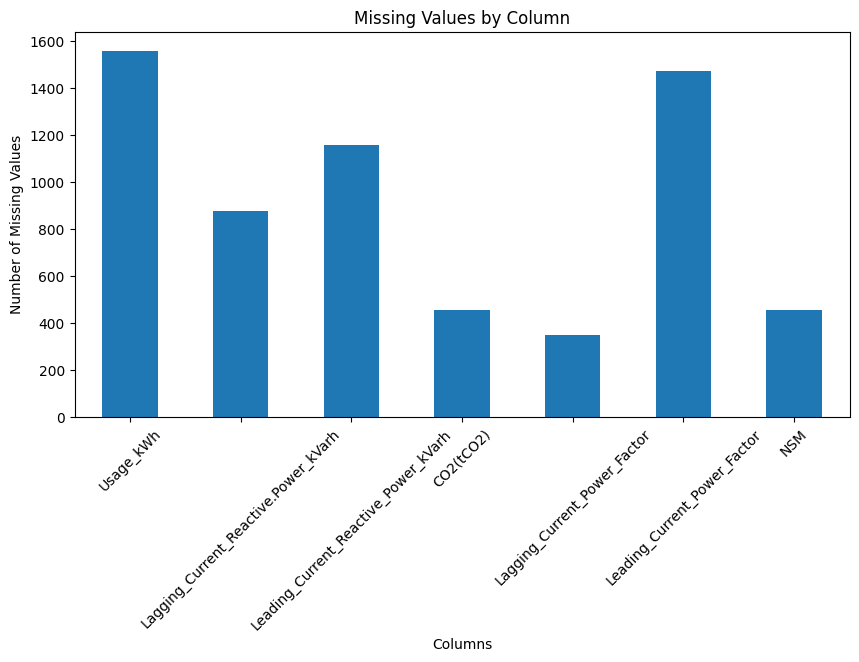

In [9]:
missing = df.isnull().sum()

missing = missing[missing > 0]

plt.figure(figsize=(10, 5))
missing.plot(kind="bar")
plt.title("Missing Values by Column")
plt.xlabel("Columns")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45)
plt.show()

**Check Duplicate Records**

In [10]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


**Convert Date_Time to Datetime**

Currently Date_Time is stored as an object/string

In [16]:
df["Date_Time"] = pd.to_datetime(df["Date_Time"])

In [17]:
df["Date_Time"].dtype

dtype('<M8[ns]')

**Sort the Data Chronologically**

In [18]:
df = df.sort_values("Date_Time").reset_index(drop=True)

In [19]:
print("First date:", df["Date_Time"].min())
print("Last date:", df["Date_Time"].max())

First date: 2018-01-01 00:00:00
Last date: 2018-12-31 23:45:00


**Target Variable Distribution**

Let’s see how many observations belong to each load type

In [20]:
df["Load_Type"].value_counts()

,count
Load_Type,
Light_Load,18073
Medium_Load,9696
Maximum_Load,7272


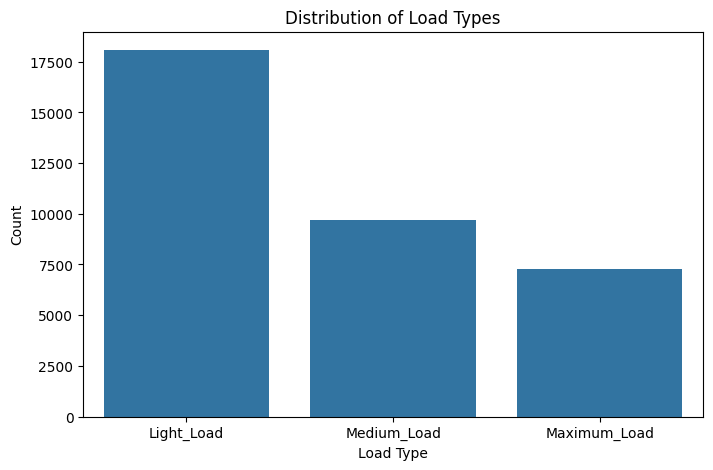

In [21]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Load_Type")

plt.title("Distribution of Load Types")
plt.xlabel("Load Type")
plt.ylabel("Count")

plt.show()

In [22]:
load_percentage = df["Load_Type"].value_counts(normalize=True) * 100

print(load_percentage)

Load_Type
Light_Load      51.576724
Medium_Load     27.670443
Maximum_Load    20.752832
Name: proportion, dtype: float64


In [23]:
df["Year"] = df["Date_Time"].dt.year
df["Month"] = df["Date_Time"].dt.month
df["Day"] = df["Date_Time"].dt.day
df["Hour"] = df["Date_Time"].dt.hour
df["Minute"] = df["Date_Time"].dt.minute
df["DayOfWeek"] = df["Date_Time"].dt.dayofweek

In [24]:
df["Is_Weekend"] = (df["DayOfWeek"] >= 5).astype(int)

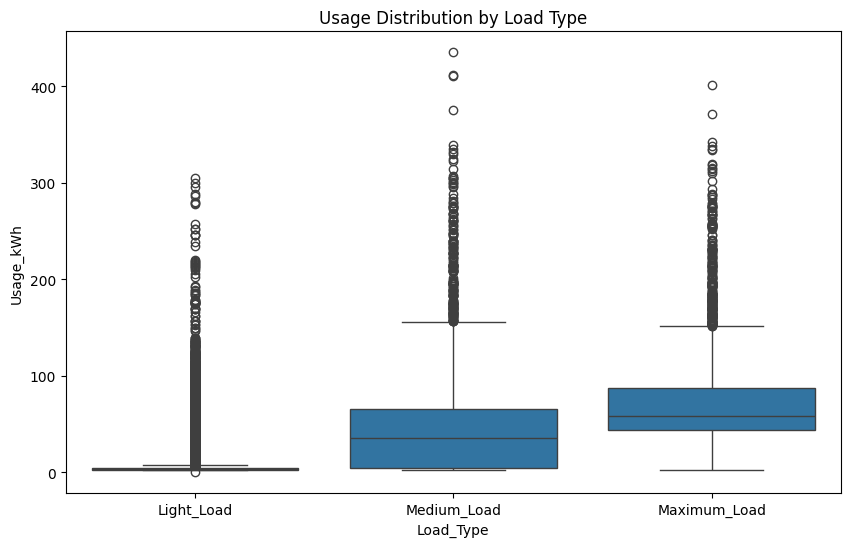

In [25]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="Load_Type",
    y="Usage_kWh"
)

plt.title("Usage Distribution by Load Type")
plt.show()

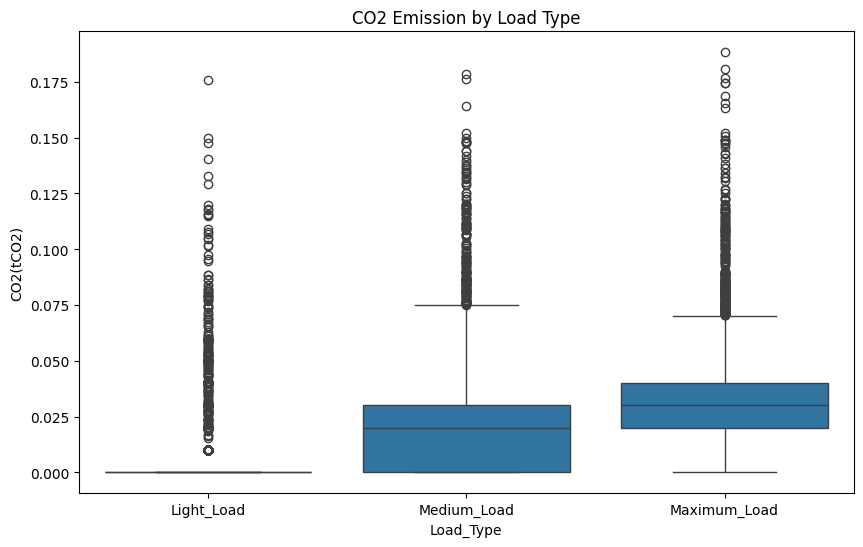

In [26]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="Load_Type",
    y="CO2(tCO2)"
)

plt.title("CO2 Emission by Load Type")
plt.show()

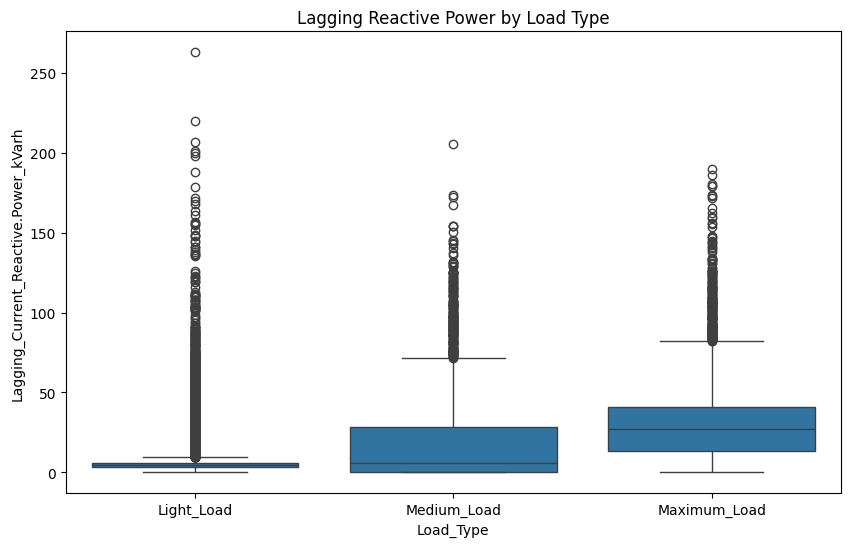

In [27]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="Load_Type",
    y="Lagging_Current_Reactive.Power_kVarh"
)

plt.title("Lagging Reactive Power by Load Type")
plt.show()

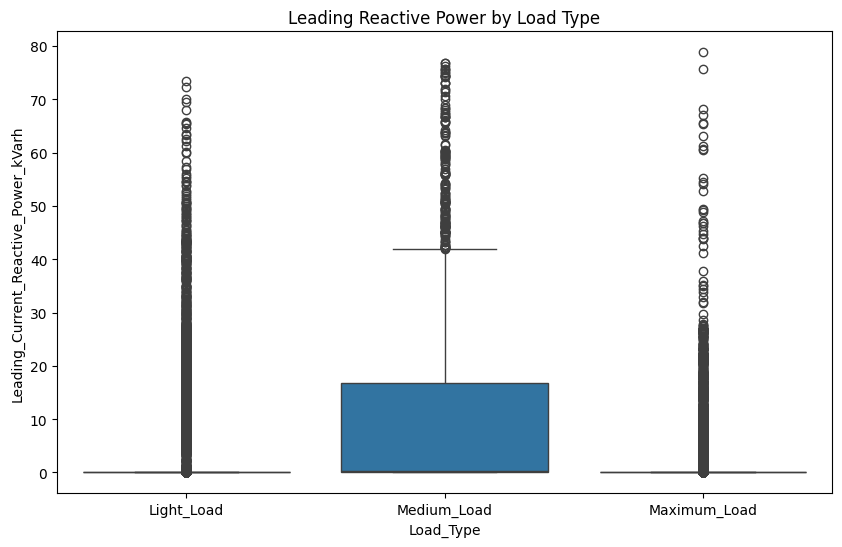

In [29]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="Load_Type",
    y="Leading_Current_Reactive_Power_kVarh"
)

plt.title("Leading Reactive Power by Load Type")
plt.show()

In [30]:
print(df.columns.tolist())

['Date_Time', 'Usage_kWh', 'Lagging_Current_Reactive.Power_kVarh', 'Leading_Current_Reactive_Power_kVarh', 'CO2(tCO2)', 'Lagging_Current_Power_Factor', 'Leading_Current_Power_Factor', 'NSM', 'Load_Type', 'Year', 'Month', 'Day', 'Hour', 'Minute', 'DayOfWeek', 'Is_Weekend']


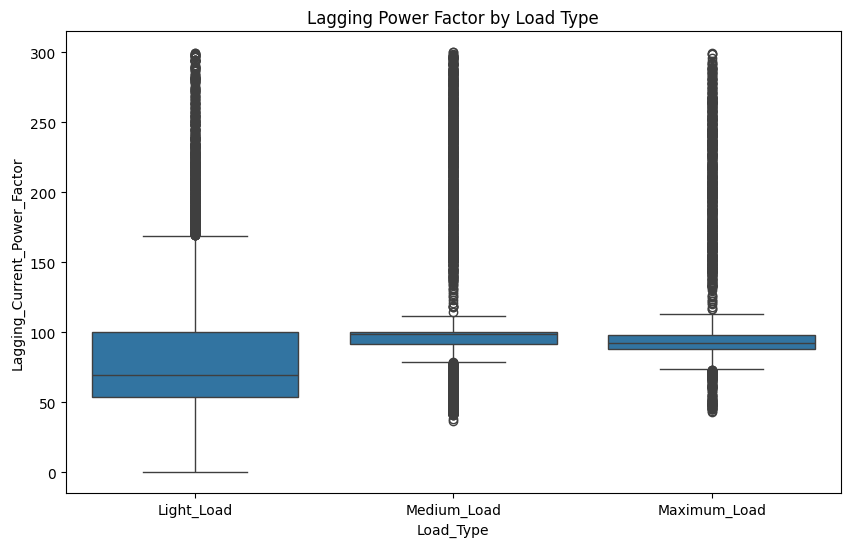

In [31]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="Load_Type",
    y="Lagging_Current_Power_Factor"
)

plt.title("Lagging Power Factor by Load Type")
plt.show()

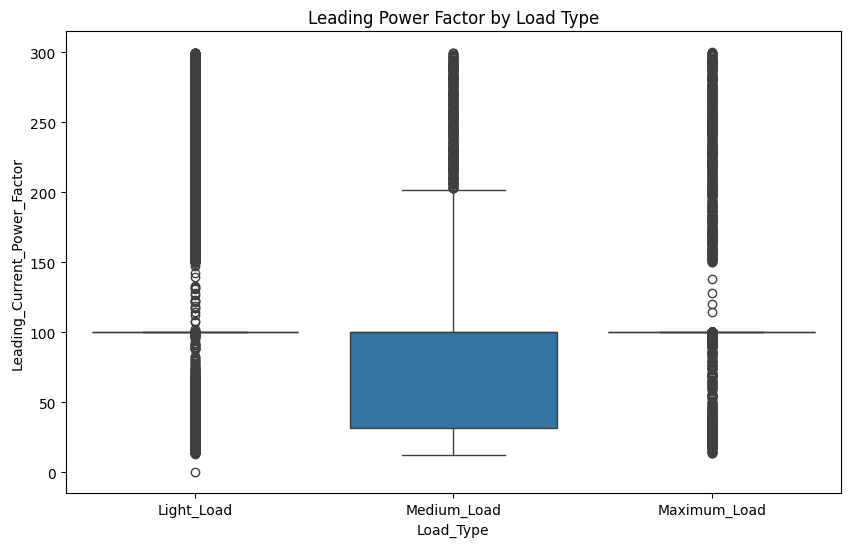

In [32]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="Load_Type",
    y="Leading_Current_Power_Factor"
)

plt.title("Leading Power Factor by Load Type")
plt.show()

**Load Type vs Time of Day**

This is particularly useful because NSM means Number of Seconds from Midnight

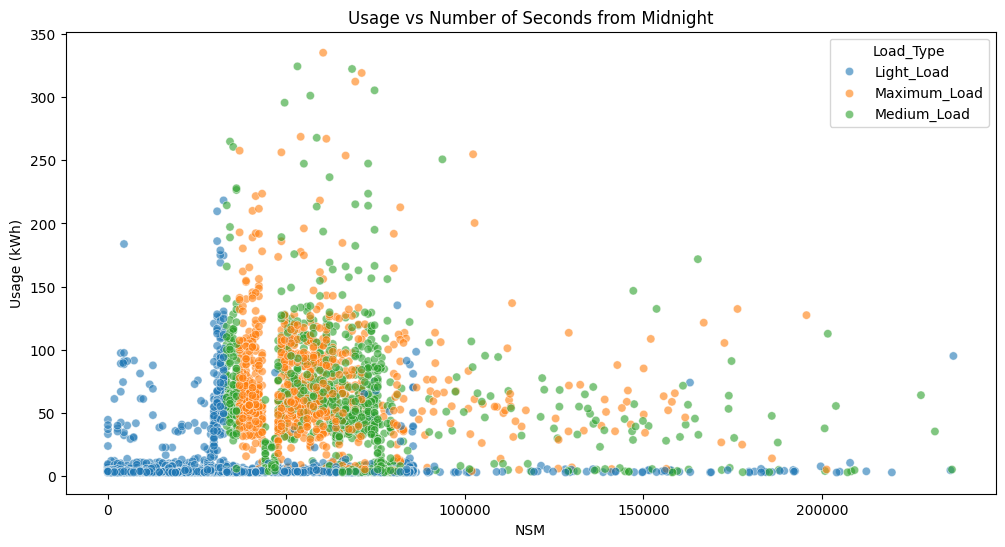

In [33]:
plt.figure(figsize=(12, 6))

sns.scatterplot(
    data=df.sample(5000, random_state=42),
    x="NSM",
    y="Usage_kWh",
    hue="Load_Type",
    alpha=0.6
)

plt.title("Usage vs Number of Seconds from Midnight")
plt.xlabel("NSM")
plt.ylabel("Usage (kWh)")

plt.show()

**Correlation Matrix**

First select numerical columns

In [34]:
numeric_columns = df.select_dtypes(include=np.number).columns

In [35]:
correlation = df[numeric_columns].corr()

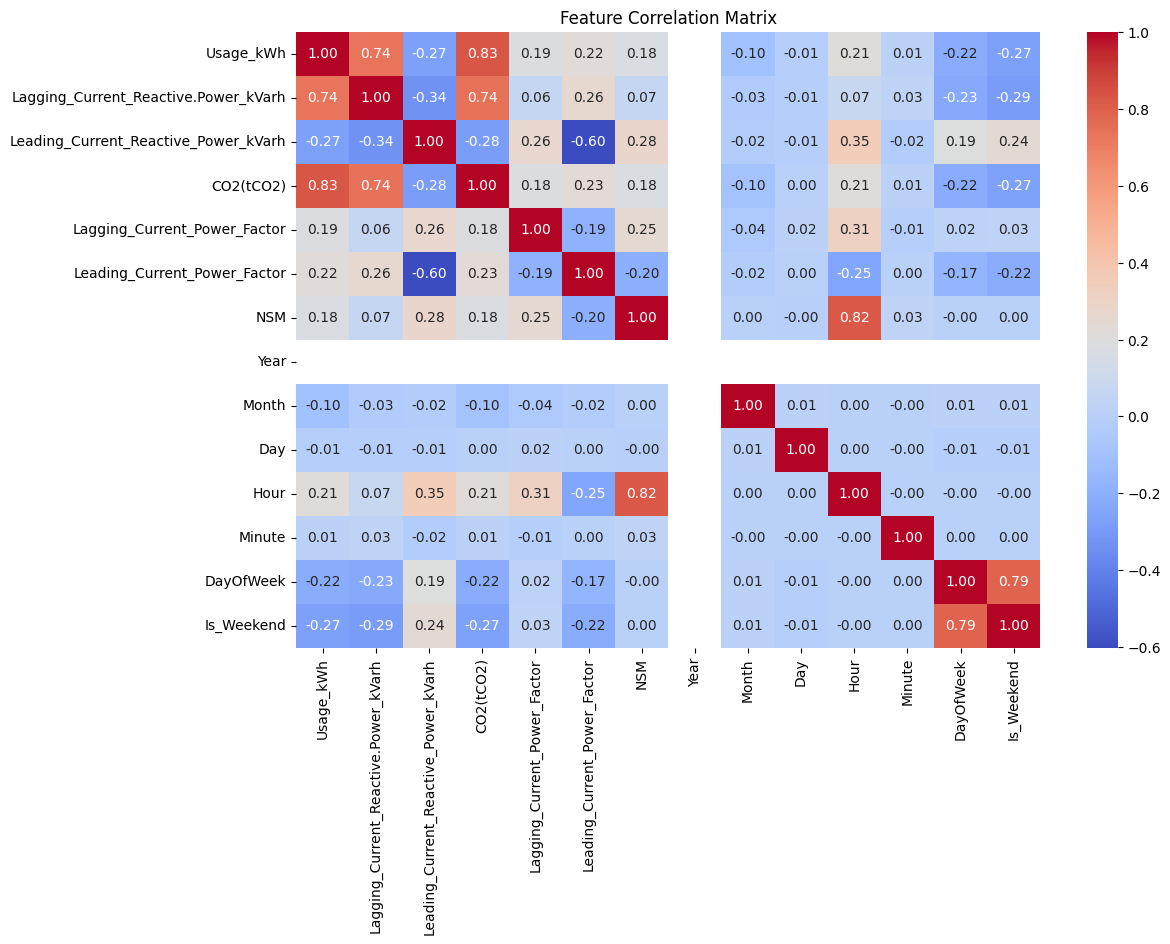

In [36]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation Matrix")

plt.show()

**Monthly Load Distribution**

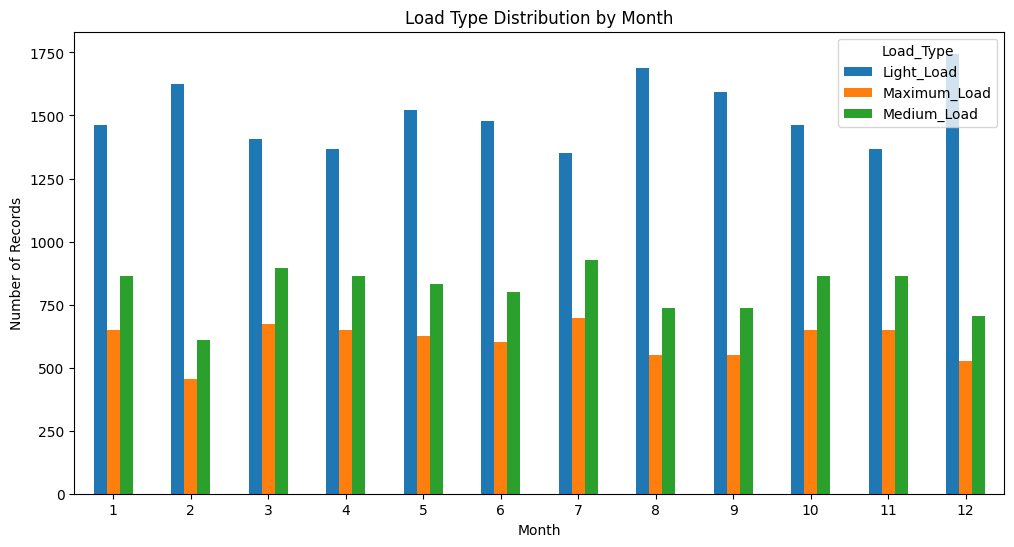

In [37]:
monthly_load = pd.crosstab(
    df["Month"],
    df["Load_Type"]
)

monthly_load.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Load Type Distribution by Month")
plt.xlabel("Month")
plt.ylabel("Number of Records")

plt.xticks(rotation=0)

plt.show()

**Average Usage by Month**

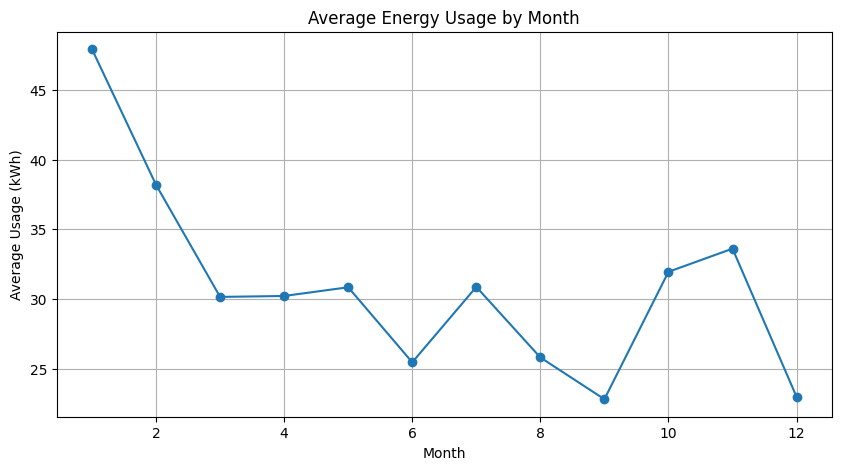

In [38]:
monthly_usage = df.groupby("Month")["Usage_kWh"].mean()

plt.figure(figsize=(10, 5))

monthly_usage.plot(marker="o")

plt.title("Average Energy Usage by Month")
plt.xlabel("Month")
plt.ylabel("Average Usage (kWh)")

plt.grid(True)

plt.show()

**Prepare Data for Machine Learning**

In [39]:
features = [
    "Usage_kWh",
    "Lagging_Current_Reactive.Power_kVarh",
    "Leading_Current_Reactive_Power_kVarh",
    "CO2(tCO2)",
    "Lagging_Current_Power_Factor",
    "Leading_Current_Power_Factor",
    "NSM",
    "Year",
    "Month",
    "Day",
    "Hour",
    "Minute",
    "DayOfWeek",
    "Is_Weekend"
]

X = df[features]

y = df["Load_Type"]

In [40]:
label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

In [41]:
for label, encoded in zip(
    label_encoder.classes_,
    label_encoder.transform(label_encoder.classes_)
):
    print(label, "=", encoded)

Light_Load = 0
Maximum_Load = 1
Medium_Load = 2


**Time-Based Train/Test Split**




In [42]:
test_month = df["Date_Time"].dt.to_period("M").max()

print("Test month:", test_month)

Test month: 2018-12


In [43]:
train_mask = df["Date_Time"].dt.to_period("M") < test_month
test_mask = df["Date_Time"].dt.to_period("M") == test_month

In [44]:
X_train = X.loc[train_mask]
X_test = X.loc[test_mask]

y_train = y_encoded[train_mask]
y_test = y_encoded[test_mask]

In [45]:
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 32064
Testing samples: 2977


In [46]:
print(
    "Training period:",
    df.loc[train_mask, "Date_Time"].min(),
    "to",
    df.loc[train_mask, "Date_Time"].max()
)

print(
    "Testing period:",
    df.loc[test_mask, "Date_Time"].min(),
    "to",
    df.loc[test_mask, "Date_Time"].max()
)

Training period: 2018-01-01 00:00:00 to 2018-11-30 23:45:00
Testing period: 2018-12-01 00:00:00 to 2018-12-31 23:45:00


**Handle Missing Values**


### Handling Missing Values

The dataset contains missing values in some numerical features. Missing values are handled using median imputation.

The median values are calculated only from the training dataset and then applied to both training and test data. This prevents information from the unseen December test set from influencing the preprocessing process and avoids data leakage.

In [47]:
imputer = SimpleImputer(strategy="median")

X_train_imputed = imputer.fit_transform(X_train)

X_test_imputed = imputer.transform(X_test)

In [48]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_imputed)

X_test_scaled = scaler.transform(X_test_imputed)

**Model 1 — Logistic Regression**

In [49]:
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(
    X_train_scaled,
    y_train
)

logistic_pred = logistic_model.predict(X_test_scaled)

In [50]:
print("Logistic Regression")
print("-------------------")

print(
    "Accuracy:",
    accuracy_score(y_test, logistic_pred)
)

print(
    "Precision:",
    precision_score(
        y_test,
        logistic_pred,
        average="weighted"
    )
)

print(
    "Recall:",
    recall_score(
        y_test,
        logistic_pred,
        average="weighted"
    )
)

print(
    "F1 Score:",
    f1_score(
        y_test,
        logistic_pred,
        average="weighted"
    )
)

Logistic Regression
-------------------
Accuracy: 0.6446086664427276
Precision: 0.704004595459887
Recall: 0.6446086664427276
F1 Score: 0.663661219489214


**Model 2 — Random Forest**

In [51]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(
    X_train_imputed,
    y_train
)

rf_pred = rf_model.predict(X_test_imputed)

In [52]:
print("Random Forest")
print("-------------")

print(
    "Accuracy:",
    accuracy_score(y_test, rf_pred)
)

print(
    "Precision:",
    precision_score(
        y_test,
        rf_pred,
        average="weighted"
    )
)

print(
    "Recall:",
    recall_score(
        y_test,
        rf_pred,
        average="weighted"
    )
)

print(
    "F1 Score:",
    f1_score(
        y_test,
        rf_pred,
        average="weighted"
    )
)

Random Forest
-------------
Accuracy: 0.9069533087000335
Precision: 0.9195198029961417
Recall: 0.9069533087000335
F1 Score: 0.9088481186566637


** Model 3 — Support Vector Machine**

In [53]:
svm_model = SVC(
    kernel="rbf",
    random_state=42
)

svm_model.fit(
    X_train_scaled,
    y_train
)

svm_pred = svm_model.predict(X_test_scaled)

In [54]:
print("Support Vector Machine")
print("---------------------")

print(
    "Accuracy:",
    accuracy_score(y_test, svm_pred)
)

print(
    "Precision:",
    precision_score(
        y_test,
        svm_pred,
        average="weighted"
    )
)

print(
    "Recall:",
    recall_score(
        y_test,
        svm_pred,
        average="weighted"
    )
)

print(
    "F1 Score:",
    f1_score(
        y_test,
        svm_pred,
        average="weighted"
    )
)

Support Vector Machine
---------------------
Accuracy: 0.7359758145784346
Precision: 0.7410767226362734
Recall: 0.7359758145784346
F1 Score: 0.7382070206627492


Model 4 — **Gradient Boosting**

In [55]:
gb_model = GradientBoostingClassifier(
    n_estimators=150,
    random_state=42
)

gb_model.fit(
    X_train_imputed,
    y_train
)

gb_pred = gb_model.predict(X_test_imputed)

In [56]:
print("Gradient Boosting")
print("-----------------")

print(
    "Accuracy:",
    accuracy_score(y_test, gb_pred)
)

print(
    "Precision:",
    precision_score(
        y_test,
        gb_pred,
        average="weighted"
    )
)

print(
    "Recall:",
    recall_score(
        y_test,
        gb_pred,
        average="weighted"
    )
)

print(
    "F1 Score:",
    f1_score(
        y_test,
        gb_pred,
        average="weighted"
    )
)

Gradient Boosting
-----------------
Accuracy: 0.8888142425260329
Precision: 0.9079344194956696
Recall: 0.8888142425260329
F1 Score: 0.89095825167769


In [69]:
print("Missing values after imputation:")
print(pd.DataFrame(X_train_imputed, columns=X_train.columns).isnull().sum().sum())

Missing values after imputation:
0


**Compare All Models**

In [57]:
models = {
    "Logistic Regression": logistic_pred,
    "Random Forest": rf_pred,
    "SVM": svm_pred,
    "Gradient Boosting": gb_pred
}

results = []

for model_name, predictions in models.items():

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(
            y_test,
            predictions
        ),
        "Precision": precision_score(
            y_test,
            predictions,
            average="weighted"
        ),
        "Recall": recall_score(
            y_test,
            predictions,
            average="weighted"
        ),
        "F1 Score": f1_score(
            y_test,
            predictions,
            average="weighted"
        )
    })

results_df = pd.DataFrame(results)

results_df

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.644609,0.704005,0.644609,0.663661
1,Random Forest,0.906953,0.919520,0.906953,0.908848
2,SVM,0.735976,0.741077,0.735976,0.738207
3,Gradient Boosting,0.888814,0.907934,0.888814,0.890958


In [58]:
results_df.sort_values(
    by="F1 Score",
    ascending=False
)

,Model,Accuracy,Precision,Recall,F1 Score
1,Random Forest,0.906953,0.919520,0.906953,0.908848
3,Gradient Boosting,0.888814,0.907934,0.888814,0.890958
2,SVM,0.735976,0.741077,0.735976,0.738207
0,Logistic Regression,0.644609,0.704005,0.644609,0.663661


**Visualize Model Performance**

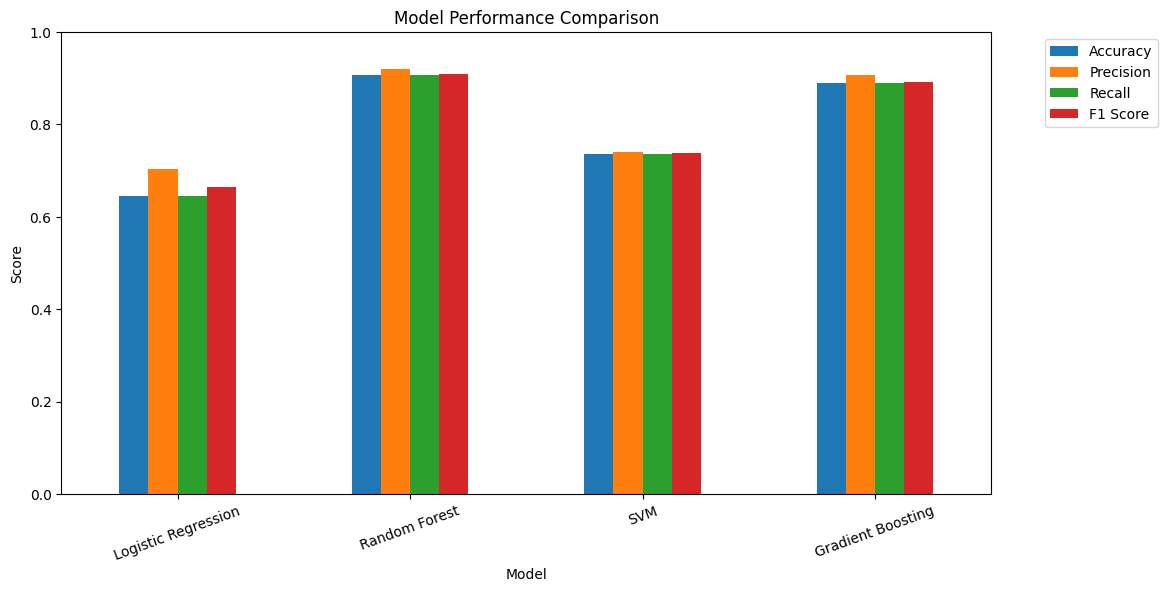

In [59]:
results_plot = results_df.set_index("Model")

results_plot.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)

plt.xticks(rotation=20)

plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.show()

**Classification Report — Best Model**

In [60]:
print(
    classification_report(
        y_test,
        rf_pred,
        target_names=label_encoder.classes_
    )
)

              precision    recall  f1-score   support

  Light_Load       0.99      0.92      0.95      1745
Maximum_Load       0.91      0.79      0.84       528
 Medium_Load       0.76      0.97      0.85       704

    accuracy                           0.91      2977
   macro avg       0.89      0.89      0.88      2977
weighted avg       0.92      0.91      0.91      2977



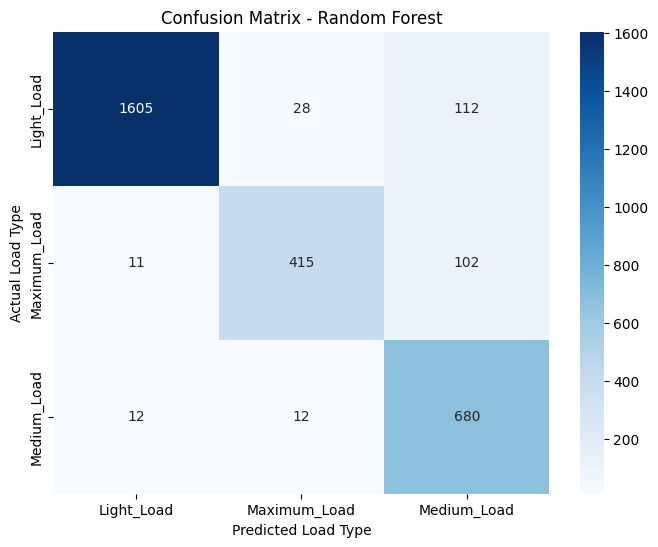

In [61]:
cm = confusion_matrix(
    y_test,
    rf_pred
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("Confusion Matrix - Random Forest")

plt.xlabel("Predicted Load Type")
plt.ylabel("Actual Load Type")

plt.show()

**Feature Importance**

One major advantage of Random Forest is that we can identify which features are important

In [62]:
 feature_importance = pd.DataFrame({
    "Feature": features,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance

,Feature,Importance
10,Hour,0.253758
6,NSM,0.221254
0,Usage_kWh,0.109152
8,Month,0.096719
3,CO2(tCO2),0.071694
4,Lagging_Current_Power_Factor,0.053705
1,Lagging_Current_Reactive.Power_kVarh,0.045743
2,Leading_Current_Reactive_Power_kVarh,0.032829
5,Leading_Current_Power_Factor,0.032348
12,DayOfWeek,0.028958


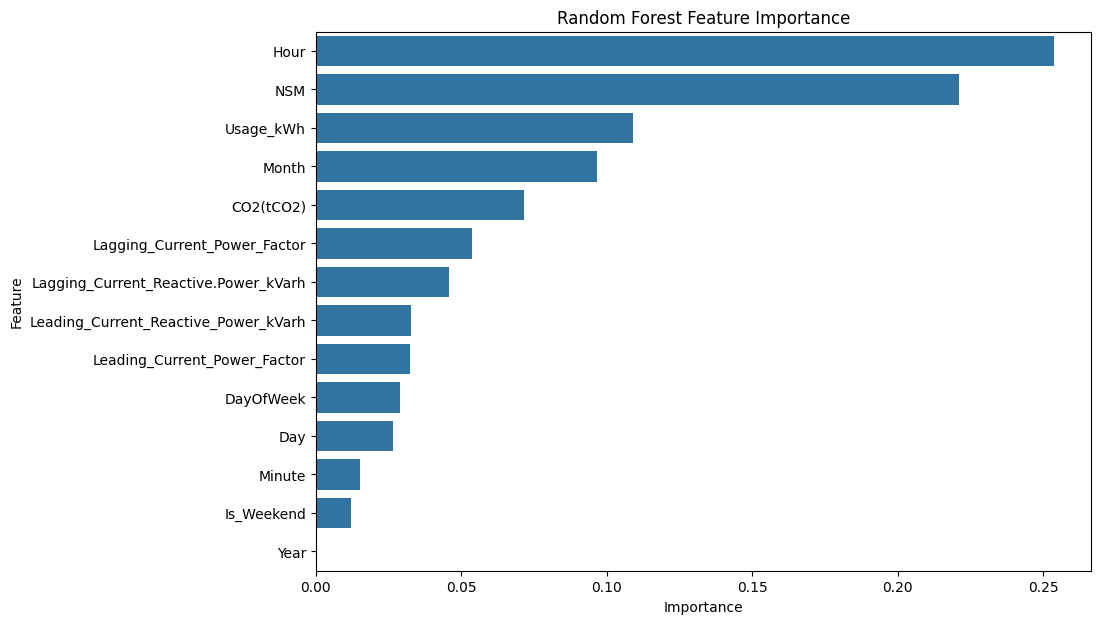

In [63]:
plt.figure(figsize=(10, 7))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")

plt.show()

**Actual vs Predicted Load Type**

In [64]:
actual_labels = label_encoder.inverse_transform(y_test)

predicted_labels = label_encoder.inverse_transform(rf_pred)

In [65]:
prediction_df = pd.DataFrame({
    "Date_Time": df.loc[test_mask, "Date_Time"].values,
    "Actual_Load_Type": actual_labels,
    "Predicted_Load_Type": predicted_labels
})

prediction_df.head(20)

,Date_Time,Actual_Load_Type,Predicted_Load_Type
0,2018-12-01 00:00:00,Light_Load,Light_Load
1,2018-12-01 00:15:00,Light_Load,Light_Load
2,2018-12-01 00:30:00,Light_Load,Light_Load
3,2018-12-01 00:45:00,Light_Load,Light_Load
4,2018-12-01 01:00:00,Light_Load,Light_Load
5,2018-12-01 01:15:00,Light_Load,Light_Load
6,2018-12-01 01:30:00,Light_Load,Light_Load
7,2018-12-01 01:45:00,Light_Load,Light_Load
8,2018-12-01 02:00:00,Light_Load,Light_Load
9,2018-12-01 02:15:00,Light_Load,Light_Load


**Check Prediction Accuracy by Class**

In [66]:
prediction_df["Correct"] = (
    prediction_df["Actual_Load_Type"]
    ==
    prediction_df["Predicted_Load_Type"]
)

prediction_df["Correct"].value_counts()

,count
Correct,
True,2700
False,277


In [67]:
prediction_df.to_csv(
    "load_type_predictions.csv",
    index=False
)

**Final Model Selection**

Automatically find the best model based on F1-score

In [68]:
best_model_row = results_df.loc[
    results_df["F1 Score"].idxmax()
]

print("Best Model:", best_model_row["Model"])
print("Accuracy:", best_model_row["Accuracy"])
print("Precision:", best_model_row["Precision"])
print("Recall:", best_model_row["Recall"])
print("F1 Score:", best_model_row["F1 Score"])

Best Model: Random Forest
Accuracy: 0.9069533087000335
Precision: 0.9195198029961417
Recall: 0.9069533087000335
F1 Score: 0.9088481186566637


**Final Conclusion**

The objective of this project was to develop a machine learning classification model capable of predicting the load type of a power system. The dataset contained historical electricity consumption, reactive power, power factor, CO₂ emission, and time-related features.

The data was preprocessed by converting the timestamp into useful temporal features and handling missing numerical values using median imputation. Exploratory data analysis was performed to understand the relationships between energy consumption, power-related features, time, and load type.

Since the dataset is time-dependent, a chronological validation strategy was used. Data from January through November 2018 was used for training, while the final month, December 2018, was kept completely unseen and used as the test set.

Multiple classification algorithms were evaluated, including Logistic Regression, Random Forest, Support Vector Machine, and Gradient Boosting. Their performance was compared using accuracy, precision, recall, and F1-score.

The model with the highest F1-score was selected as the final model. The results demonstrate the ability of machine learning techniques to classify power-system load conditions using historical operational and temporal information.